## Анализ данных о Нобелевских лауреатах

### **Контекст проекта**
В этом задании мы будем работать с датасетом о лауреатах Нобелевской премии. Ваша задача — распарсить и проанализировать эти данные, ответив на ключевые вопросы о закономерностях вручения премий, демографических характеристиках лауреатов и исторических тенденциях.

### **Этап 1: Подготовка данных**

**Задача:** На этом этапе вам надо собрать структурированный список словарей с информацией о лауреатах и призах. Приведем начало нужного нам датасета.

``` {code:python}
[{'id': '745',
  'name': 'A. Michael Spence',
  'gender': 'male',
  'birth_year': 1943,
  'country_birth': 'USA',
  'country_now': 'USA',
  'prizes_relevant': [{'prize_amount': 10000000,
    'prize_amount_adjusted': 15547541,
    'award_year': 2001,
    'category_en': 'Economic Sciences',
    'prize_status': 'received'}],
  'type_': 'person'},
 {'id': '102',
  'name': 'Aage N. Bohr',
  'gender': 'male',
  'birth_year': 1922,
  'country_birth': 'Denmark',
  'country_now': 'Denmark',
  'prizes_relevant': [{'prize_amount': 630000,
    'prize_amount_adjusted': 4304697,
    'award_year': 1975,
    'category_en': 'Physics',
    'prize_status': 'received'}],
  'type_': 'person'}]
  ```

Поскольку информация о лауреатах-людях и лауреатах-организациях структурирована по-разному, а также из-за того, что часть полей в json могут отсутстввовать, необходимо реализовать функции для процессинга словарей, которые будут достаточно обобщаемыми для обоих типов данных.

**Что нужно сделать:**

На входе информация о конкретном лауреате представляет из себя кучу вложенных друг в друга словарей. Из этой структуры нам надо получить плоский словарь вида {atribute: value}, где atribute --- это один из небольшого множества интересных нам атрибутов. При этом в исходном файле
1. пути к атрибутам могут иметь разную длину
2. атрибуты могут отсутствовать
3. атрибуты могут нуждаться в дополнительной обработке (например, поле id в исходных словарях записано как строка.)

Поскольку наивная реализация такого обработчика оказывается довольно громоздкой, вам нужно создать файл json_dict_processing.py, в котором реализован высокоуровневый функционал для решения задачи "обработать вложенный json-словарь"

Главное требование к интерфейсу:
по (вложенному) словарю о лауреате и конфигу (см ниже) надо получить плоский словарь вида {atribute: value}.

Достичь этого можно, например, таким набором функций

* `extract_nested_value(obj, keys)` - извлекает значение из вложенных структур данных по цепочке ключей

* `process_dictionary_with_config(dictionary, config)` - обрабатывает один словарь согласно словару-конфигу (формат конфига см ниже.)

* `process_list_of_dicts_with_config(list_of_dicts, config)` - обрабатывает список словарей, эта функция нужна чтобы обработать список призов.

* `create_processor(config, list_processor=False)` - создает готовый процессор с предзагруженной конфигурацией. В случае, если list_processor == True, внутрь процессора подается process_list_of_dicts_with_config, иначе process_dictionary_with_config.

**Замечание насчет последней функции.**

Планируемое применение этой функции примерно такое:
`laureate_processor = create_processor(PERSON_CONFIG, list_processor=False)`

То есть, create_processor возвращает функцию, которая реализует функционал process_dictionary_with_config но с уже заполненным конфигом. Это повышает читаемость кода и снижает риск перепутать конфиги из-за дублирования кода.


Помимо этого нужно создать файлы-конфиги для данных по призам, лауреатам-людям, и лауреатам-организациям.

КОНФИГ для функций process_dictionary_with_config и process_list_of_dicts_with_config имеет следующий вид
```python
  {'атрибут_который_берем_сырым': ['путь', 'к', 'данным'],  # или
  'атрибут_который_нужно_обработать': (['путь', 'к', 'данным'], функция_обработки)}
  ```
В случае, если атрибут можно взять в итоговый датасет сырым, в values() словаря-конфига будет список path_list.
Если же атрибут еще надо обработать, для него в поле config[attribute] будет tuple вида (path_list, function).

Примеры атрибутов, которые можно взять сырыми: имя, размер приза. Примеры атрибутов, которые нужно обработать: год вручения приза (в сырых данных есть только полная дата, записанная как строка)

После того, как будет создан core.py, создайте конфиги laureates_configs.py и prizes_configs.py

Постарайтесь провалидировать код с помощью assert-ов, вызываемых в ноутбуке или в .py-файлах.

пример использования:

assert 1 == True

**Валидация**

В вашем случае assert должен взять простой словарик с одним вложенным полем и какой-нибудь конфиг-файл.
Также убедитесь, что при обработке данных собственно по лауреатам в них нет странностей (смотрите ниже)

**Атрибуты для ПРИЗА (CONFIG_PRIZE, prizes_configs.py)**

- `prize_amount` - сумма приза → `prizeAmount`
- `prize_amount_adjusted` - скорректированная сумма приза → `prizeAmountAdjusted`
- `award_year` - год вручения приза (преобразуется в целое число) → `awardYear`
- `category_en` - категория на английском → `category.en`
- `prize_status` - статус приза → `prizeStatus`

**Атрибуты для ЧЕЛОВЕКА-ЛАУРЕАТА (CONFIG_PERSON, laureates_configs.py)**

- `id` - уникальный идентификатор → `id`
- `name` - имя лауреата → `knownName.en`
- `gender` - пол → `gender`
- `birth_year` - год рождения (извлекается из даты) → `birth.date`
- `country_birth` - страна рождения → `birth.place.country.en`
- `country_now` - текущая страна → `birth.place.countryNow.en`
- `prizes_relevant` - список призов лауреата → `nobelPrizes` (обрабатывается процессором призов, который вы задаете в конфиге для призов)

**Атрибуты для ОРГАНИЗАЦИИ-ЛАУРЕАТА (CONFIG_ORG, laureates_configs.py)**

- `id` - уникальный идентификатор → `id`
- `name` - название организации → `orgName.en`
- `founded_year` - год основания (извлекается из даты) → `founded.date`
- `country_founded` - страна основания → `founded.place.country.en`
- `country_now` - текущая страна → `founded.place.countryNow.en`
- `prizes_relevant` - список призов организации → `nobelPrizes` (обрабатывается процессором призов, который вы задаете в конфиге для призов)

**Вспомогательные функции:**

- `process_year(year_string)` - извлекает год из строки даты (формат "YYYY-MM-DD"). Функция находится в файле laureates_configs.py
- `prize_processor()` - создает процессор для обработки списков призов. Функция находится в файле prizes_configs.py
- `person_processor()` - создает процессор для данных о людях-лауреатах. Функция находится в файле laureates_configs.py
- `org_processor()` - создает процессор для данных об организациях-лауреатах. Функция находится в файле laureates_configs.py

In [1]:
%pip install requests matplotlib

Note: you may need to restart the kernel to use updated packages.


## 1. Подготовка к анализу

Повторяющиеся операции, которые могут пригодиться в разных частях проекта, вынесены, соответственно требованиям проекта, в отдельные  `.py`-файлы (обработка вложенного JSON, группировка записей, расчёт статистик и построение графиков). В ноутбуке оставляем функции, которые нужны непосредственно для нашего исследования.
Инструкции по установке библиотек и запуску проекта находятся в `README.md`.

In [2]:
import json
from pathlib import Path
from pprint import pprint

from aggregations import (
    count_records,
    max_value,
    mean_value,
    median_value,
    top_n,
)
from attribute_manager import add_attribute
from checks import run_checks, validate_dataset
from data_loader import load_laureates
from dataset_helpers import (
    apply_aggregations,
    count_missing,
    filter_records,
    group_by_attributes,
    summarize_groups,
)
from laureates_configs import process_orgs, process_persons
from presentation import CATEGORY_LABELS, plot_bars, plot_lines, print_table
from stopwords import STOPWORDS

### 1.1. Проверяем базовые функции

Перед работой с реальным датасетом запускаем небольшие тесты:
они проверяют обработку пропусков, конфигурации JSON, группировки,
агрегации и неизменность исходных словарей.

In [3]:
run_checks()
print(
    'Проверки конфигураций, вложенных полей, '
    'пропусков и агрегаций пройдены.'
)

Проверки конфигураций, вложенных полей, пропусков и агрегаций пройдены.


## 2. Загрузка и обработка исходных данных

Сначала загружаем данные с помощью `load_laureates()`. Функция проверяет, есть ли уже сохранённый файл `data/laureates.json`. Если он есть, используем его, а если нет, то отправляем запросы к Nobel Prize API и загружаем данные частями. После загрузки дополнительно проверяем, что количество полученных записей совпадает со значением `meta.count`.

Сохранённый JSON позволяет повторно запускать анализ без обращения к API, что удобно, так как работа не зависит от доступности сервера и при одинаковых исходных данных даёт те же результаты. Если понадобится получить свежие данные, можно вызвать `load_laureates(refresh=True)`. В таком случае после обновления нужно будет заново проверить расчёты и выводы.

In [4]:
payload = load_laureates()
print('Источник:', payload['source'])
print('Дата загрузки (UTC):', payload['downloaded_at'])
print('Всего исходных записей:', len(payload['laureates']))

Источник: https://api.nobelprize.org/2.1/laureates
Дата загрузки (UTC): 2026-11-08T08:06:08.681697+00:00
Всего исходных записей: 1028


### 2.1. Приводим JSON к одному формату

В API структура человека и организации различается: у человека
указаны сведения о рождении, у организации же указаны сведения о ее основании.
Используем два конфига из `laureates_configs.py`, а список премий
обрабатывается отдельным конфигом из `prizes_configs.py`. В результате получаем список обычных словарей с одинаковой структурой. В них сохраняются только нужные нам поля: имя, ID, год рождения или основания, страна и информация о наградах. Если какого-то значения нет в исходных данных, записываем None. Годы и идентификаторы дополнительно приводим к целым числам.

In [5]:
def get_laureate_data(laureate: dict) -> dict:
    """Определяем тип лауреата и преобразовываем его данные.

    В Nobel Prize API лауреатами могут быть как отдельные люди, так и
    организации. Т.к. структура их данных различается, сначала нужно
    определить тип записи.

    Если в исходном словаре есть поле knownName, лауреат считается
    человеком и обрабатывается через process_persons. Если есть orgName,
    то он является организацией, для которой используется process_orgs.

    После обработки в словарь добавляется поле type_, чтобы в дальнейшем
    можно было легко разделять людей и организации при расчёте статистик.

    Args:
        laureate: Исходный словарь одного лауреата из API.

    Returns:
        Обработанный словарь с нужными полями и типом лауреата.

    Raises:
        ValueError: Если по структуре записи невозможно
            определить, человек это или организация.
    """
    if 'knownName' in laureate:
        processed = process_persons(laureate)
        processed['type_'] = 'person'
    elif 'orgName' in laureate:
        processed = process_orgs(laureate)
        processed['type_'] = 'org'
    else:
        raise ValueError('Не удалось определить тип лауреата.')
    return processed

После обработки проверяем, что количество лауреатов совпадает с метаданными API, ID не повторяются, а годы и суммы наград находятся в допустимых пределах. Также выведем одну запись, чтобы посмотреть, как теперь выглядят данные.

In [6]:
laureates_data = [get_laureate_data(row) for row in payload['laureates']]
validate_dataset(laureates_data, payload)
pprint(laureates_data[0], sort_dicts=False)

{'id': 745,
 'name': 'A. Michael Spence',
 'gender': 'male',
 'birth_year': 1943,
 'country_birth': 'USA',
 'country_now': 'USA',
 'prizes_relevant': [{'prize_amount': 10000000,
                      'prize_amount_adjusted': 15547541,
                      'award_year': 2001,
                      'category_en': 'Economic Sciences',
                      'prize_status': 'received',
                      'motivation': 'for their analyses of markets with '
                                    'asymmetric information'}],
 'type_': 'person'}


Отдельно необходимо учесть, что в исходном API не всегда указана полная дата. Например, из `1917-00-00` можно достать год рождения (1917), хотя день и месяц неизвестны. А значение `0000-00-00` не содержит информации о годе, поэтому для него оставляем `None`.

### **Этап 2: EDA лауреатов**

EDA или Exploratory Data Analysis - первый шаг при работе с любыми данными.

Чтобы начать работать с этой секцией, проведите проведите чисто технический анализ собранных данных.

1. Сколько всего записей?
2. Все ли значения полей заполнены?
3. Если нет, сколько пропусков в каждом из полей? Выведите ответ на этот вопрос в формате `{'field_name': missing_values}`. А какая доля пропусков?
5. Каковы максимальные и минимальные значения поля id и каким годам награждения они соответствуют? Есть ли записи с повторяющимися id? Есть ли пары айди, которые в отсортированном массиве айдишников различаются более, чем на один?

При реализации ответов на эти вопросы, пользуйтесь теми же принципами, что описаны выше. Можете начать с плохого хакерского кода, однако в таком случае в маркдауне пропишите, как будете его обобщать и разносить по функциям и модулям. (об этом ниже)

В основном EDA пользуйтесь аккуратным кодом, разбитым на функции и файлы.

## 3. Техническая проверка данных (EDA)

Перед основным анализом посмотрим, насколько полные и корректные у нас данные. Для этого проверим количество лауреатов и награждений, наличие пропусков, повторяющихся ID и разрывов в их последовательности. Также найдём лауреатов с минимальным и максимальным ID.

Учтем, что один лауреат может получить несколько премий. Следовательно, для технического анализа награждений отдельно разворачиваем список премий: каждая награда становится самостоятельной записью.

In [7]:
def make_prize_rows(laureates: list) -> list:
    """Создаем отдельную запись для каждого награждения.

    В исходных данных один лауреат представлен одним словарём, внутри
    которого хранится список всех его Нобелевских премий.

    Для некоторых задач удобнее анализировать не лауреатов, а сами
    награждения, поэтому функция будет разворачивать вложенный список
    prizes_relevant в отдельные записи.

    К каждой награде добавляются ID и имя лауреата, его тип, пол,
    современная страна и десятилетие получения премии.

    Args:
        laureates: Список обработанных лауреатов.

    Returns:
        Список словарей, где одна запись соответствует
        одной премии конкретного лауреата.
        
    """
    prize_rows = []

    for laureate in laureates:
        for prize in laureate['prizes_relevant'] or []:
            row = prize.copy()
            row.update({
                'laureate_id': laureate['id'],
                'name': laureate['name'],
                'type_': laureate['type_'],
                'gender': laureate.get('gender'),
                'country_now': laureate['country_now'],
                'award_decade': prize['award_year'] // 10 * 10,
            })
            prize_rows.append(row)
    return prize_rows

In [8]:
prize_rows = make_prize_rows(laureates_data)
first_year = min(row['award_year'] for row in prize_rows)
last_year = max(row['award_year'] for row in prize_rows)
print('Период:', first_year, '-', last_year)

Период: 1901 - 2026


### 3.1. Пропуски, дубликаты и границы ID

Для подсчёта пропусков используем функцию `count_missing`. Данные о людях, организациях и наградах проверяем отдельно, потому что у них разные наборы полей. Например, информация о поле предусмотрена только для людей, поэтому её отсутствие у организаций не считается пропуском. Также проверяем ID лауреатов на повторы. Учтем, что пропуски в последовательности номеров сами по себе не означают, что часть данных не загрузилась.

In [9]:
def technical_analysis(laureates: list, prize_rows: list) -> dict:
    """Проводим технический анализ качества исходных данных.

    Сначала функция выводит общее количество лауреатов и отдельных записей о
    награждениях.

    Затем рассчитывают количество и доля пропусков по всем полям.
    Отдельно анализирую людей, организации и вложенные данные о премиях,
    т.к. наборы их полей различаются.

    После этого проверяются идентификаторы лауреатов: ищутся повторяющиеся
    ID, определяются минимальный и максимальный ID, а также промежутки между
    соседними ID, в которых есть пропущенные номера.

    Args:
        laureates: Список обработанных лауреатов.
        prize_rows: Список отдельных записей о награждениях.

    Returns:
        Словарь с количеством и долями пропусков,
        повторяющимися ID, промежутками между ID
        и информацией о крайних идентификаторах.
    """
    print('\nПроведем технический анализ:')
    print('Всего лауреатов:', len(laureates))
    print('Записей о награждении:', len(prize_rows))
    missing = count_missing(laureates)
    print('Пропуски по всем полям:', missing)
    shares = {
        field: round(count / len(laureates), 4)
        for field, count in missing.items()
    }
    print('Доли пропусков от 0 до 1:', shares)
    for laureate_type in ['person', 'org']:
        selected = filter_records(
            laureates, lambda row: row['type_'] == laureate_type,
        )
        print(laureate_type, '- записей:', len(selected),
              'пропуски:', count_missing(selected))

    prize_fields = [
        prize for laureate in laureates
        for prize in laureate['prizes_relevant'] or []
    ]
    print('Пропуски в полях наград:', count_missing(prize_fields))
    print('Доли пропусков в наградах:', {
        field: round(count / len(prize_fields), 4)
        for field, count in count_missing(prize_fields).items()
    })
    id_groups = group_by_attributes(laureates, ['id'])
    duplicates = sorted(key[0] for key, rows in id_groups.items()
                        if len(rows) > 1)
    sorted_ids = sorted(key[0] for key in id_groups)
    extremes = []
    for laureate_id in [sorted_ids[0], sorted_ids[-1]]:
        laureate = id_groups[(laureate_id,)][0]
        extremes.append({
            'id': laureate_id,
            'name': laureate['name'],
            'years': sorted(prize['award_year']
                            for prize in laureate['prizes_relevant']),
        })
    print_table(extremes, {'id': 'ID', 'name': 'Лауреат', 'years': 'Годы'})
    gaps = [
        (left, right) for left, right in zip(sorted_ids, sorted_ids[1:])
        if right - left > 1
    ]
    print('Повторяющиеся ID:', duplicates)
    print('Соседние ID с разницей больше 1:', gaps)
    print('Все значения заполнены:', not any(missing.values()))
    return {'missing': missing, 'missing_shares': shares,
            'duplicates': duplicates, 'gaps': gaps, 'extremes': extremes}

In [10]:
technical = technical_analysis(laureates_data, prize_rows)


Проведем технический анализ:
Всего лауреатов: 1028
Записей о награждении: 1036
Пропуски по всем полям: {'birth_year': 28, 'country_birth': 31, 'country_founded': 1004, 'country_now': 7, 'founded_year': 1001, 'gender': 28, 'id': 0, 'name': 0, 'prizes_relevant': 0, 'type_': 0}
Доли пропусков от 0 до 1: {'birth_year': 0.0272, 'country_birth': 0.0302, 'country_founded': 0.9767, 'country_now': 0.0068, 'founded_year': 0.9737, 'gender': 0.0272, 'id': 0.0, 'name': 0.0, 'prizes_relevant': 0.0, 'type_': 0.0}
person - записей: 1000 пропуски: {'birth_year': 0, 'country_birth': 3, 'country_now': 3, 'gender': 0, 'id': 0, 'name': 0, 'prizes_relevant': 0, 'type_': 0}
org - записей: 28 пропуски: {'country_founded': 4, 'country_now': 4, 'founded_year': 1, 'id': 0, 'name': 0, 'prizes_relevant': 0, 'type_': 0}
Пропуски в полях наград: {'award_year': 0, 'category_en': 0, 'motivation': 0, 'prize_amount': 0, 'prize_amount_adjusted': 0, 'prize_status': 0}
Доли пропусков в наградах: {'award_year': 0.0, 'categ

**Что получилось?** В снимке **1028 уникальных лауреатов**:
1000 людей и 28 организаций. Всего **1036 награждений**, потому что
некоторые лауреаты получали премию повторно. Дубликатов ID нет.
Минимальный ID - 1 (Вильгельм Рентген, 1901 год), максимальный -
1070 (Michael Woodford, 2026 год). Число записей совпало с `meta.count`.

Страна рождения отсутствует у трёх людей, страны основания нет
у четырёх организаций, год основания отсутствует у одной организации. Современная страна рождения/основания (`country_now`) неизвестна у семи
лауреатов, что есть **0,68%** выборки. Пропуски анализируем по типам объектов, так как не все поля применимы к организациям.

Поскольку это курс по Python, а не по статистике или визуализации данных, мы не задаем жесткие рамки того, что вы должны проанализировать.
Однако это отличная возможность представить себя в роли разработчика базы данных или, например, библиотеки pandas.

В коде нужно соблюдать следующие правила:

1. должны быть реализованы  несколько способов работы с данными (среднее/медианное/максимальное значение метрики, количество примеров, вывод топ-N объектов по значению метрики).
2. анализ выбранных вами тем должен включать в себя анализ метрик в тотале, по категориям и в динамике по годам или десятилетиям.
3. проанализировать стоит 2-3 темы. Вы можете использовать темы ниже или взять свои.
2. вывод ноутбука должен быть понятен обывателю. Это может быть визуализация в matplotlib/seaborn. Сопровождайте вывод markdown-ячейками с вашими  мыслями, пояснениями и инсайтами, которые удалось извлечь.
3. Нельзя использовать pandas и numpy, но можно вдохновляться их интерфейсом и функционалом при дизайне ваших функций.


Из пункта 2 следует, что вам придется работать не только с атрибутами лауреатов, но и самих призов.
Информацию о призах нужно доставать и записывать как атрибут уже лауреата. Функции, работающие с призами (например, факт того, что лауреат отказался от какого-то из призов) можно реализовать в ноутбуке, но если вы создаете более общие вспомогательные функции, выносите их в отдельные модули.

Мы рекомендуем следующую структуру кода:

* `dataset_helpers.py` в котором реализованы фильтрация списка словарей (плоских) по условиям (аналог sql-ного where), а также аналог sql-ного групбая. А также функция для применения агрегаций к списку словарей
* `aggregations.py` в котором реализованы функции расчета среднего/медианы/других эвристик и мб вывод топ n-значений по какой-то метрике.
* `atribute_manager.py` в котором реализован переиспользуемый интерфейс для добавления (и мб удаления) полей.

Замечание насчет group-by.

На игрушесном примере она может работать примерно так:
```
    Входные данные: [
        {'name': 'Alice', 'country': 'USA', 'age': 25},
        {'name': 'Bob', 'country': 'UK', 'age': 30},
        {'name': 'Charlie', 'country': 'USA', 'age': 25}
    ]
    
    group_by_attributes(data, ['country', 'age']) → {
        ('USA', 25): [
            {'name': 'Alice', 'country': 'USA', 'age': 25},
            {'name': 'Charlie', 'country': 'USA', 'age': 25}
        ],
        ('UK', 30): [
            {'name': 'Bob', 'country': 'UK', 'age': 30}
        ]
    }
```

Замечание насчет agregations.py
1. Агрегации соответственно должны применяться к спискам вида [
    {'name': 'Alice', 'country': 'USA', 'age': 25},
    {'name': 'Charlie', 'country': 'USA', 'age': 25}
]
2. Пользуйтесь модулем statistics из стандартной библиотеки питона.


Эта структура одна из возможных для организации вашего кода, главное, чтобы эти достаточно общие функции блыи переиспользованы

----------

При анализе данных вам понадобятся более конкретные функции, например filter_by_num_prizes или output_metric_by_category. Их пишите прямо в ноутбуке и сопровождайте коментами.

Ниже мы приводим некоторые примеры вопросов, которые может быть интересно задать к данным, но если у вас есть желание, можете поисследовать датасет с любой интересной вам стороны!


**2.1. Топ-статистика по странам**
- Определите топ-5 стран по общему количеству лауреатов
- Постройте аналогичные рейтинги отдельно по категориям (физика, химия, медицина и т.д.)

**2.2. Возраст при награждении**
- Рассчитать средний возраст лауреатов на момент получения **первого** приза. Рассмотрите только лауреатов-людей.
- Исследуйте, как средний возраст получения первого приза различается по категориям
- Различаются ли средний и медианный возрасты?

**2.3. Гендерное распределение**
- Как менялось количество женщин-лауреатов по десятилетиям?
- Сравните распределение лауреаток по категориям. Выведите значения суммарно за все годы и по декадам.
- В какой из категорий больше всего женщин лауреаток изначально и в последние пару десятилетий?

**2.4. Миграции лауреатов**
- У скольки лауреатов исходная страна и страна на момент вручения нобелевской премии различаются? Всегда ли это различие объясняется миграцией? Добавьте вспомогательное поле 'country_of_origin_adjusted_for_migration', чтобы различие между этим полем и страной на момент вручения объяснялось миграцией.
- Выявите страны с наибольшей долей "оттекших" и "притекших" лауреатов.
- Есть ли оттоки среди организаций?

**2.5. Многократные лауреаты**
- Найдите лауреатов, получившие больше одного приза. Кто получил больше 2 раз?
- Совпадает ли категория второго приза с первой?  
- Сколько в среднем времени прошло между получением первой и второй премии?

**2.6 Отказы от премий**
- Определите, в каких категориях чаще отказывались от премий?
- Есть ли отказы среди организаций?

## 4. Анализ выбранных тем

Для всех трёх направлений используем одинаковый подход: сначала смотрим общие результаты, затем сравниваем категории и изменения по десятилетиям.
При этом учитываем все факты присуждения премий, даже если лауреат впоследствии отказался от награды. Для анализа также определяем год первой премии, десятилетие и возраст человека на момент первого награждения.
Дополнительно формируем отдельную таблицу с уникальными парами «лауреат - категория». Это нужно, чтобы человек, получивший несколько премий в одной категории, не учитывался несколько раз при сравнении категорий.

In [11]:
def prepare_analysis_data(laureates: list) -> list:
    """Подготавливаем дополнительные признаки для основного анализа.

    Функция последовательно добавляет три новых поля.

    first_award_year - год самой ранней Нобелевской премии конкретного
    лауреата.

    first_decade - десятилетие этой премии, например 1990 для награждения
    в 1995 году.

    age_first_prize - приблизительный возраст человека при получении первой
    премии. Он рассчитывается как разница между годом награждения и годом
    рождения, без учёта дня и месяца.

    Очевидно, что организаций возраст не рассчитывается. Если год рождения
    неизвестен, значение также остаётся None.

    Новые поля добавляются через add_attribute, поэтому исходные словари не
    изменяются.

    Args:
        laureates: Список обработанных людей и организаций.

    Returns:
        Новый список словарей с тремя дополнительными полями.
    """
    prepared = add_attribute(
        laureates, 'first_award_year',
        lambda row: min(prize['award_year']
                        for prize in row['prizes_relevant']),
    )
    prepared = add_attribute(
        prepared, 'first_decade',
        lambda row: row['first_award_year'] // 10 * 10,
    )
    prepared = add_attribute(
        prepared, 'age_first_prize',
        lambda row: row['first_award_year'] - row['birth_year']
        if row['type_'] == 'person' and row['birth_year'] is not None
        else None,
    )
    return prepared


def make_category_rows(laureates: list) -> list:
    """Создаю записи для анализа лауреатов по категориям премии.

    Один лауреат может получать Нобелевскую премию несколько раз, в том
    числе в одной и той же категории.

    Если просто считать все награждения, такой лауреат будет учитываться
    несколько раз. Так, функция создаёт отдельную запись для каждой
    уникальной пары «лауреат - категория».

    Для этого премии одного лауреата группируются по категории. Если в одной
    категории было несколько наград, они объединяются в одну запись.

    Дополнительно рассчитывается category_first_year - год первой премии
    лауреата именно в этой категории.

    Args:
        laureates: Список подготовленных лауреатов
            с информацией обо всех премиях.

    Returns:
        Список словарей, в котором каждый лауреат
        встречается не более одного раза в каждой категории.
    """
    category_rows = []
    for laureate in laureates:
        groups = group_by_attributes(laureate['prizes_relevant'],
                                     ['category_en'])
        for (category,), prizes in groups.items():
            row = laureate.copy()
            row['category_en'] = category
            row['category_first_year'] = min(
                prize['award_year'] for prize in prizes
            )
            category_rows.append(row)
    return category_rows

In [12]:
prepared = prepare_analysis_data(laureates_data)
category_rows = make_category_rows(prepared)
decades = list(range(first_year // 10 * 10, last_year // 10 * 10 + 1, 10))
results_dir = Path('results')
figures_dir = results_dir / 'figures'

### 4.1. Страны рождения и основания

**Вопрос**: какие страны чаще всего встречаются среди лауреатов и как менялась география награждений со временем?

Для людей используем современную страну места рождения, а для организаций берем современную страну основания (`country_now`). Семь записей без известной страны в рейтинги не включаем.

В общем рейтинге каждый лауреат учитывается один раз. При сравнении категорий повторные награждения в одной категории также не создают новых наблюдений. Для динамики учитываем десятилетие первой премии. При этом первая и последняя декады неполные, поэтому их абсолютные значения нужно сравнивать осторожно.

In [13]:
def analyze_countries(laureates: list, category_rows: list,
                      decades: list, figures_dir, show: bool = False) -> dict:
    """Проанализируем распределение лауреатов по странам.

    Для анализа используется поле country_now (современная страна места
    рождения человека или основания организации).

    Сначала исключаются записи, для которых страна неизвестна.
    Затем рассчитывается количество уникальных лауреатов в каждой стране
    и определяется общий топ-5.

    Далее для каждой категории Нобелевской премии строится отдельный рейтинг
    стран. Здесь используются category_rows, чтобы повторные награждения
    одного лауреата в одной категории не увеличивали счётчик.

    Последним этапом здесь будет анализ динамики по десятилетия.
    Для пяти ведущих стран считаем, сколько лауреатов впервые получили
    премию в каждом десятилетии.

    В результате строятся два графика: общий рейтинг стран и динамика первых
    награждений по десятилетиям.

    Args:
        laureates: Подготовленный список уникальных лауреатов.
        category_rows: Записи уникальных пар
            «лауреат - категория».
        decades: Список десятилетий для анализа.
        figures_dir: Папка для сохранения графиков.
        show: Нужно ли отображать графики на экране.

    Returns:
        Словарь с общим топ-5 стран, рейтингами по категориям,
        динамикой по десятилетиям и количеством лауреатов
        с известной страной.
    """
    print('\n1. Страны рождения и основания.')
    with_country = filter_records(
        laureates, lambda row: row['country_now'] is not None,
    )
    ranking = top_n(summarize_groups(
        with_country, ['country_now'], {'count': count_records},
    ), 'count')
    print('Страна известна:', len(with_country), 'из', len(laureates))
    print_table(ranking, {'country_now': 'Страна', 'count': 'Лауреатов'})

    by_category = []
    category_groups = group_by_attributes(category_rows, ['category_en'])
    for (category,), members in sorted(category_groups.items()):
        filled_members = filter_records(
            members, lambda row: row['country_now'] is not None,
        )
        leaders = top_n(summarize_groups(
            filled_members, ['country_now'], {'count': count_records},
        ), 'count')
        for leader in leaders:
            by_category.append({'category': category, **leader})
    print('\nТоп-5 в каждой категории (уникальные лауреаты внутри категории):')
    print_table(by_category, {'category': 'Категория', 'country_now': 'Страна',
                              'count': 'Лауреатов'})

    countries = [row['country_now'] for row in ranking]
    groups = group_by_attributes(with_country, ['first_decade', 'country_now'])
    by_decade = []
    for decade in decades:
        row = {'decade': decade}
        for country in countries:
            row[country] = len(groups.get((decade, country), []))
        by_decade.append(row)
    plot_bars(ranking, 'country_now', 'count',
              'Топ-5 стран: уникальные люди и организации', 'Лауреатов',
              Path(figures_dir) / 'countries_top5.png', show)
    plot_lines(by_decade, 'decade', dict(zip(countries, countries)),
               'Когда лауреаты стран топ-5 получили первую премию',
               'Лауреатов с первой премией в десятилетии',
               Path(figures_dir) / 'countries_decades.png', show)
    return {'top5': ranking, 'by_category': by_category,
            'by_decade': by_decade, 'known_country_count': len(with_country)}


1. Страны рождения и основания.
Страна известна: 1021 из 1028
Страна         | Лауреатов
---------------+----------
USA            | 306      
United Kingdom | 96       
Germany        | 86       
France         | 66       
Japan          | 32       

Топ-5 в каждой категории (уникальные лауреаты внутри категории):
Категория              | Страна          | Лауреатов
-----------------------+-----------------+----------
Chemistry              | USA             | 59       
Chemistry              | Germany         | 26       
Chemistry              | United Kingdom  | 26       
Chemistry              | France          | 12       
Chemistry              | Japan           | 9        
Economic Sciences      | USA             | 56       
Economic Sciences      | United Kingdom  | 7        
Economic Sciences      | Canada          | 5        
Economic Sciences      | France          | 5        
Economic Sciences      | the Netherlands | 4        
Literature             | France          | 12 

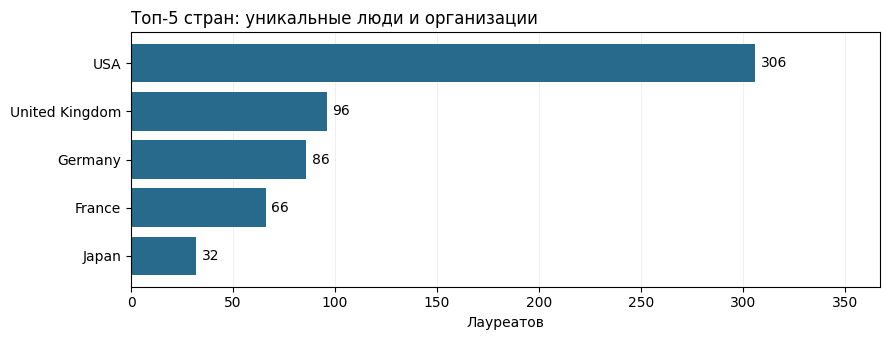

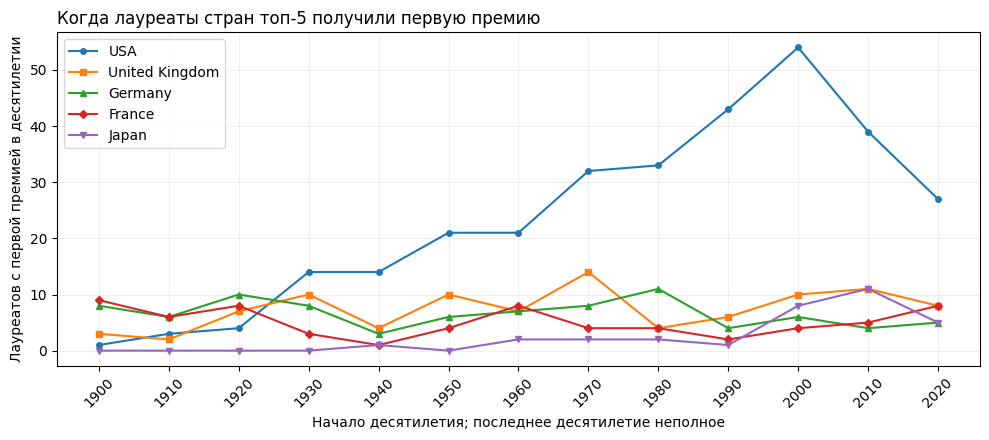

In [14]:
countries = analyze_countries(
    prepared, category_rows, decades, figures_dir, show=True,
)

**Вывод**. Страна происхождения известна у **1021** лауреата. В общем рейтинге с большим отрывом лидируют США (306 лауреатов). Далее идут Великобритания (96), Германия (86), Франция (66) и Япония (32). Таким образом, в США родились или были основаны более чем в три раза больше лауреатов, чем в Великобритании.

По таблицам также можно посмотреть, какие страны чаще встречаются в разных категориях, а график показывает, как менялось количество первых награждений у стран-лидеров со временем.

При этом важно помнить, что мы анализируем именно страну происхождения. По этим данным нельзя определить, куда лауреаты переезжали и какая страна обеспечила им условия для научной или творческой работы.

### 4.2. Возраст при получении первой премии

**Вопрос**: в каком возрасте лауреаты впервые получают Нобелевскую премию и насколько этот возраст различается между категориями и десятилетиями?

Возраст рассчитываем как разницу между годом первой премии и годом рождения.
Если человек получал премию несколько раз, учитываем только его первое награждение. При сравнении категорий также смотрим на категорию именно первой премии, чтобы один человек не попадал сразу в несколько групп.

In [15]:
def analyze_age(laureates: list, category_rows: list,
                decades: list, figures_dir, show: bool = False) -> dict:
    """Исследую возраст лауреатов при получении первой премии.

    В анализ включаются только люди, ведь возраст организаций здесь не
    рассматривается.

    Сначала отбираются лауреаты, для которых удалось рассчитать возраст при
    первой премии. Затем вычисляются основные статистики: количество людей,
    средний возраст, медиана и максимальное значение.

    Далее возраст сравнивается между категориями. Для этого учитываются
    только те категории, в которых человек получил свою самую первую премию.
    Таким образом, повторное награждение в более позднем возрасте не влияет
    на результат.

    После этого рассчитывается динамика возраста по десятилетиям первой
    премии, а также определяются пять самых молодых и пять самых старших
    лауреатов.

    В конце строятся графики среднего возраста по категориям и изменения
    среднего и медианного возраста во времени.

    Args:
        laureates: Подготовленный список лауреатов.
        category_rows: Записи по уникальным категориям лауреатов.
        decades: Список десятилетий для анализа.
        figures_dir: Папка для сохранения графиков.
        show: Нужно ли выводить графики на экран.

    Returns:
        Словарь с общими статистиками возраста,
        результатами по категориям и десятилетиям,
        а также списками самых молодых и старших лауреатов.
    """
    print('\n2. Возраст при первой премии.')
    people = filter_records(laureates, lambda row: row['type_'] == 'person')
    with_age = filter_records(
        people, lambda row: row['age_first_prize'] is not None,
    )
    # Для категорий берём только категории самого первого награждения.
    first_categories = filter_records(
        category_rows,
        lambda row: row['type_'] == 'person'
        and row['age_first_prize'] is not None
        and row['category_first_year'] == row['first_award_year'],
    )
    metrics = {
        'count': count_records,
        'mean_age': lambda rows: mean_value(rows, 'age_first_prize'),
        'median_age': lambda rows: median_value(rows, 'age_first_prize'),
        'max_age': lambda rows: max_value(rows, 'age_first_prize'),
    }
    total = apply_aggregations(with_age, metrics)
    print('Возраст известен:', len(with_age), 'из', len(people), 'людей')
    print_table([total], {'count': 'Людей', 'mean_age': 'Средний возраст',
                          'median_age': 'Медиана', 'max_age': 'Максимум'})
    by_category = sorted(
        summarize_groups(first_categories, ['category_en'], metrics),
        key=lambda row: row['mean_age'],
    )
    print_table(by_category, {'category_en': 'Первая категория',
                              'count': 'Людей', 'mean_age': 'Среднее',
                              'median_age': 'Медиана', 'max_age': 'Максимум'})
    groups = group_by_attributes(with_age, ['first_decade'])
    by_decade = []
    for decade in decades:
        summary = apply_aggregations(groups.get((decade,), []), metrics)
        by_decade.append({'decade': decade, **summary})
    print_table(by_decade, {'decade': 'Десятилетие', 'count': 'Людей',
                            'mean_age': 'Среднее', 'median_age': 'Медиана'})
    age_extremes = {}
    for title, reverse in [
        ('Самые молодые:', False), ('Самые старшие:', True),
    ]:
        leaders = top_n(with_age, 'age_first_prize', reverse=reverse)
        age_extremes[title] = leaders
        print('\n' + title)
        print_table(leaders, {'name': 'Лауреат', 'age_first_prize': 'Возраст',
                              'first_award_year': 'Год первой премии'})
    plot_bars(by_category, 'category_en', 'mean_age',
              'Средний возраст при первой премии по категориям',
              'Лет: год премии минус год рождения',
              Path(figures_dir) / 'age_categories.png', show)
    plot_lines(by_decade, 'decade',
               {'mean_age': 'Среднее', 'median_age': 'Медиана'},
               'Возраст при первой премии по десятилетиям', 'Лет',
               Path(figures_dir) / 'age_decades.png', show)
    return {'total': total, 'by_category': by_category,
            'by_decade': by_decade, 'extremes': age_extremes}


2. Возраст при первой премии.
Возраст известен: 1000 из 1000 людей
Людей | Средний возраст | Медиана | Максимум
------+-----------------+---------+---------
1000  | 60.61           | 61.00   | 97      
Первая категория       | Людей | Среднее | Медиана | Максимум
-----------------------+-------+---------+---------+---------
Physics                | 230   | 57.79   | 56.00   | 96      
Physiology or Medicine | 235   | 59.02   | 58      | 87      
Chemistry              | 199   | 59.43   | 58      | 97      
Peace                  | 112   | 60.97   | 62.00   | 87      
Literature             | 123   | 65.04   | 67      | 88      
Economic Sciences      | 101   | 67.21   | 67      | 90      
Десятилетие | Людей | Среднее | Медиана
------------+-------+---------+--------
1900        | 56    | 57.84   | 58.00  
1910        | 37    | 53.08   | 50     
1920        | 54    | 54.98   | 56.00  
1930        | 55    | 51.62   | 49     
1940        | 40    | 58.02   | 56.00  
1950        | 71    |

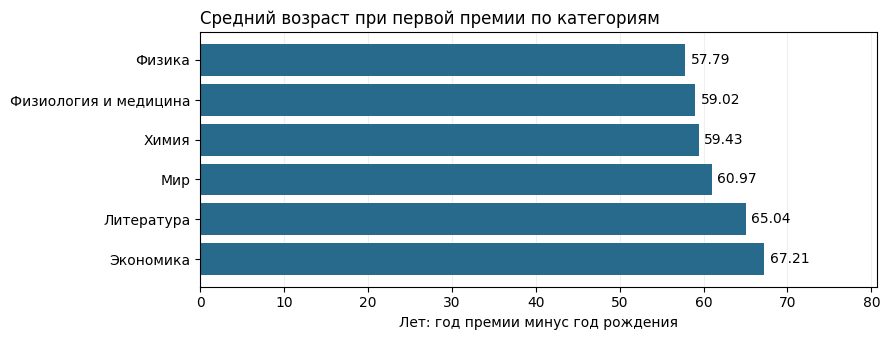

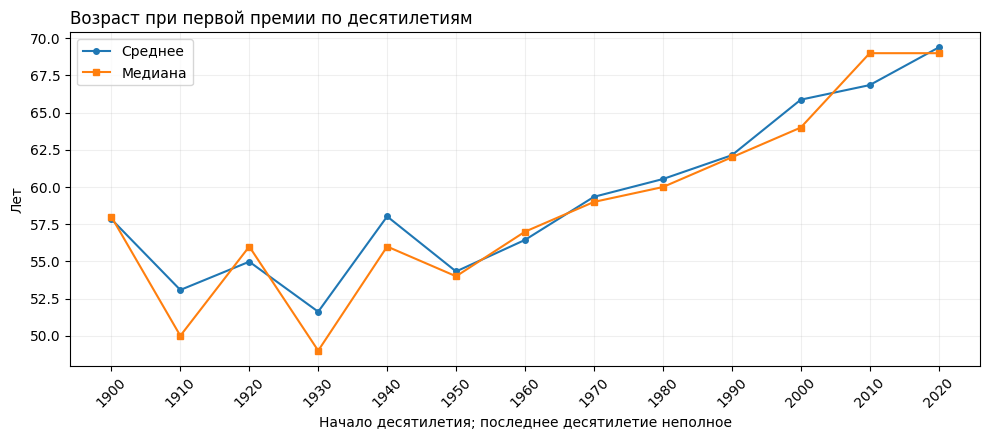

In [16]:
age = analyze_age(prepared, category_rows, decades, figures_dir, show=True)

**Вывод.** У всех 1000 лауреатов-людей известен год рождения, поэтому пропусков при расчёте возраста нет. В среднем первую Нобелевскую премию получают в **60,61 года**, медианный возраст - **61 год**. При этом возраст заметно различается по категориям: раньше всего первую премию получают физики (в среднем в **57,79 года**), а позже всего получают экономисты (**67,21 года**). Максимальный возраст при первом награждении составил **97 лет**.

По динамике видно, что со временем первую премию стали получать позже. Если в 1900-х средний возраст составлял **57,84 года**, то в 2010-х он вырос до **66,85 года**, а в 2020-х достиг **69,38 года**. При этом рост был неравномерным. Также стоит учитывать, что данные за 2020-е ещё неполные, а состав категорий со временем менялся: например, премия по экономике появилась только в 1969 году. Следовательно, часть изменений может объясняться не только возрастом лауреатов, но и изменением структуры самих награждений.

### 4.3. Гендерное распределение

**Вопрос**: как менялось количество женщин среди лауреатов и в каких категориях они встречаются чаще?

Если человек получал премии в разные десятилетия, он учитывается в каждом из них по одному разу. Например, один лауреат может попасть в статистику и за 1900-е, и за 1910-е годы. Поэтому сумма по десятилетиям может быть больше количества уникальных лауреатов за всю историю.

Долю женщин рассчитываем среди людей с известным полом. Чтобы сравнение начала и конца истории было более корректным, дополнительно рассматриваем два периода одинаковой продолжительности: **1901-1920** и **2007-2026**.

In [17]:
def gender_statistics(people: list) -> dict:
    """Рассчитаем гендерное распределение среди лауреатов-людей.

    Функция считает количество женщин и мужчин по значениям поля gender.
    Дополнительно определяется количество людей, у которых пол не указан как
    male или female.

    Долю женщин будем рассчитывать только среди людей с известным полом, а
    не от общего количества записей, чтобы пропущенные или неизвестные
    значения не искажали полученный процент.

    Args:
        people: Список словарей с данными о людях.

    Returns:
        Словарь с общим количеством записей,
        количеством женщин, мужчин, неизвестных значений
        и процентом женщин среди людей с известным полом.

        Если пол неизвестен у всех, вместо процента
        возвращается None.
    """
    women = len(filter_records(
        people, lambda row: row.get('gender') == 'female',
    ))
    men = len(filter_records(people, lambda row: row.get('gender') == 'male'))
    known = women + men
    return {'count': len(people), 'women': women, 'men': men,
            'unknown': len(people) - known,
            'women_pct': 100 * women / known if known else None}

In [18]:
def analyze_gender(laureates: list, category_rows: list, prize_rows: list,
                   decades: list, figures_dir, show: bool = False) -> dict:
    """Исследую гендерное распределение Нобелевских лауреатов.

    Сначала рассчитывается общее количество женщин и мужчин, а также доля
    женщин среди лауреатов с известным полом.

    Затем гендерное распределение рассматривается отдельно по категориям
    премии. Для этого используются category_rows: если человек дважды
    получал премию в одной категории, он всё равно учитывается в ней
    только один раз.

    Для анализа по десятилетиям применяю другой подход. Каждый человек
    учитывается один раз в каждом десятилетии, когда он получал хотя бы одну
    премию. Так, один лауреат может попасть в несколько десятилетий, но не
    будет повторно посчитан внутри одного.

    Отдельно рассчитывается количество уникальных женщин по сочетаниям
    категории и десятилетия.

    Также сравниваются первые и последние 20 лет в доступных данных.
    Учтем, что повторные награждения одной женщины в одной категории внутри
    периода не увеличивают количество лауреаток.

    В конце строятся графики количества женщин по категориям и динамики по
    десятилетиям.

    Args:
        laureates: Список уникальных лауреатов.
        category_rows: Записи уникальных пар
            «лауреат - категория».
        prize_rows: Список отдельных награждений.
        decades: Список десятилетий для анализа.
        figures_dir: Папка для сохранения графиков.
        show: Нужно ли отображать графики на экране.

    Returns:
        Словарь с общим гендерным распределением,
        статистиками по категориям и десятилетиям,
        количеством женщин в категориях по десятилетиям
        и сравнением первых и последних 20 лет.
    """
    print('\n3. Гендерное распределение')
    people = filter_records(laureates, lambda row: row['type_'] == 'person')
    category_people = filter_records(
        category_rows, lambda row: row['type_'] == 'person',
    )
    total = gender_statistics(people)
    print_table([total], {'count': 'Людей', 'women': 'Женщин', 'men': 'Мужчин',
                          'unknown': 'Пол неизвестен',
                          'women_pct': 'Женщин, %'})
    by_category = []
    category_groups = group_by_attributes(category_people, ['category_en'])
    for (category,), members in sorted(category_groups.items()):
        by_category.append({'category_en': category,
                            **gender_statistics(members)})
    print_table(by_category, {'category_en': 'Категория', 'women': 'Женщин',
                              'count': 'Людей', 'women_pct': 'Женщин, %'})
    person_prizes = filter_records(
        prize_rows, lambda row: row['type_'] == 'person',
    )
    unique_per_decade = [members[0] for members in group_by_attributes(
        person_prizes, ['laureate_id', 'award_decade'],
    ).values()]
    decade_groups = group_by_attributes(unique_per_decade, ['award_decade'])
    by_decade = [
        {'decade': decade,
         **gender_statistics(decade_groups.get((decade,), []))}
        for decade in decades
    ]
    print('\nКаждый человек учтён один раз в каждом десятилетии награждения:')
    print_table(by_decade, {'decade': 'Десятилетие', 'count': 'Людей',
                            'women': 'Женщин', 'women_pct': 'Женщин, %'})

    women_prizes = filter_records(
        person_prizes, lambda row: row['gender'] == 'female',
    )
    unique_category_decades = [members[0] for members in group_by_attributes(
        women_prizes, ['laureate_id', 'category_en', 'award_decade'],
    ).values()]
    groups = group_by_attributes(
        unique_category_decades, ['award_decade', 'category_en'],
    )
    categories = sorted(key[0] for key in category_groups)
    category_decades = []
    for decade in decades:
        row = {'decade': decade}
        for category in categories:
            row[category] = len(groups.get((decade, category), []))
        category_decades.append(row)
    print('\nУникальные женщины внутри каждой категории и десятилетия:')
    print_table(category_decades, {'decade': 'Декада', **{
        category: CATEGORY_LABELS[category] for category in categories
    }})

    first_year = min(row['award_year'] for row in prize_rows)
    last_year = max(row['award_year'] for row in prize_rows)
    periods = [(first_year, first_year + 19), (last_year - 19, last_year)]
    period_counts = []
    for start, end in periods:
        selected = filter_records(
            prize_rows, lambda row: row['gender'] == 'female'
            and start <= row['award_year'] <= end,
        )
        unique_people = [rows[0] for rows in group_by_attributes(
            selected, ['laureate_id', 'category_en'],
        ).values()]
        counts = group_by_attributes(unique_people, ['category_en'])
        for category in categories:
            period_counts.append({'period': f'{start}–{end}',
                                  'category_en': category,
                                  'women': len(counts.get((category,), []))})
    print('\nПервые и последние 20 лет в данных; повторные премии убраны:')
    print_table(period_counts, {'period': 'Период', 'category_en': 'Категория',
                                'women': 'Уникальных женщин'})
    plot_bars(top_n(by_category, 'women', number=len(by_category)),
              'category_en', 'women', 'Женщины-лауреаты по категориям',
              'Уникальных женщин внутри категории',
              Path(figures_dir) / 'gender_categories.png', show)
    plot_lines(by_decade, 'decade', {'women': 'Женщины'},
               'Число женщин по десятилетиям награждения', 'Женщин',
               Path(figures_dir) / 'gender_decades.png', show)
    return {'total': total, 'by_category': by_category, 'by_decade': by_decade,
            'category_decades': category_decades,
            'period_counts': period_counts}


3. Гендерное распределение
Людей | Женщин | Мужчин | Пол неизвестен | Женщин, %
------+--------+--------+----------------+----------
1000  | 69     | 931    | 0              | 6.90     
Категория              | Женщин | Людей | Женщин, %
-----------------------+--------+-------+----------
Chemistry              | 8      | 200   | 4.00     
Economic Sciences      | 3      | 101   | 2.97     
Literature             | 19     | 123   | 15.45    
Peace                  | 21     | 113   | 18.58    
Physics                | 5      | 230   | 2.17     
Physiology or Medicine | 14     | 235   | 5.96     

Каждый человек учтён один раз в каждом десятилетии награждения:
Десятилетие | Людей | Женщин | Женщин, %
------------+-------+--------+----------
1900        | 56    | 3      | 5.36     
1910        | 38    | 1      | 2.63     
1920        | 54    | 2      | 3.70     
1930        | 55    | 3      | 5.45     
1940        | 40    | 3      | 7.50     
1950        | 71    | 0      | 0.00     
1960

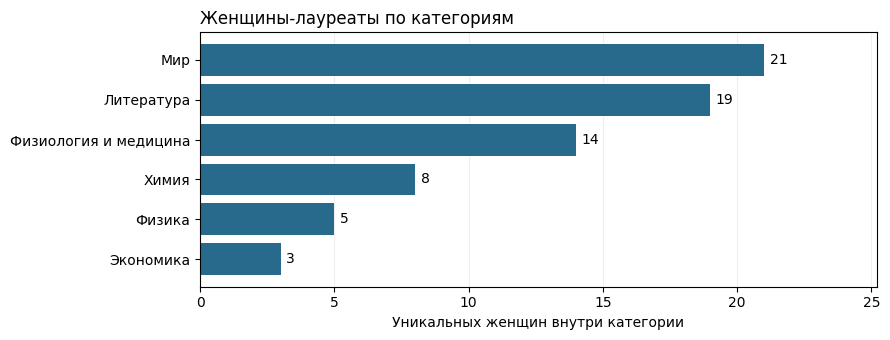

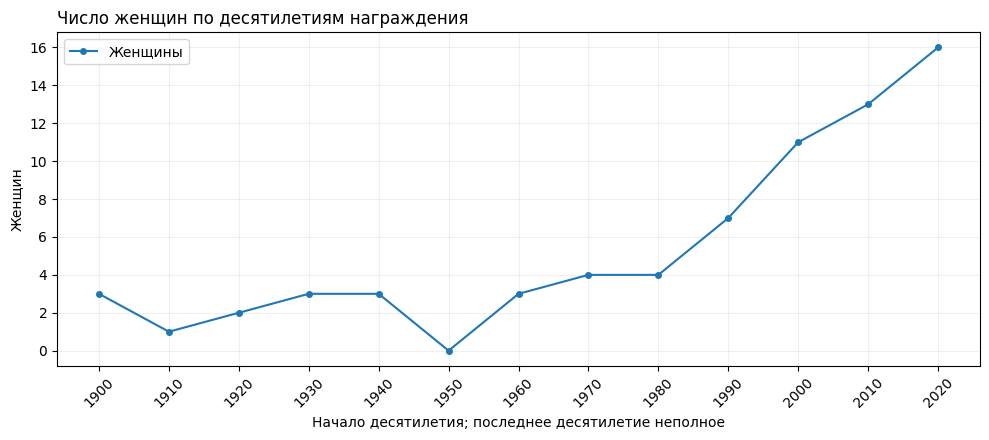

In [19]:
gender = analyze_gender(
    prepared, category_rows, prize_rows, decades, figures_dir, show=True,
)

**Вывод**. Среди 1000 лауреатов-людей нашлось 69 женщин (6,90%) и 931 мужчин. Больше всего женщин за всю историю получили премию мира (21), на втором месте литература (19). В премии мира также самая высокая доля женщин среди лауреатов этой категории (**18,58%**).

В первые двадцать лет в физике, химии, литературе и премии мира было по одной лауреатке. В период с 2007 по 2026 год больше всего женщин было в литературе и премии мира (по девять в каждой категории). В раннем периоде экономической премии ещё не существовало, поэтому сравнивать её с другими категориями за это время нельзя.

В неполных 2020-х женщины составляют **16 из 82 лауреатов (19,51%)**, что намного больше, чем общий показатель за всю историю, но десятилетие ещё не закончилось, значит, пока рано сравнивать его абсолютные значения с предыдущими полными десятилетиями.

---------

## Бонусное задание на +2 балла


### Лингвистический анализ мотиваций**

**5.1. Анализ текстов мотиваций**
- Соберите корпус текстов мотиваций вручения премий. Для этого измените конфиг обработки призов.
- Выделите самые частые топ-50 слов. Какие из этих слов самые частые в принципе в английском языке (такие, как for, the и другие), а какие кажутся важными именно в контексте вручения Нобелевской премии (например, 'chemistry')?
- Самые частые слова, которые также являются частыми во всем английском языке занесите в отдельный конфиг-файл под названием `stopwords.py`. Вычистите их из текстов. Какие слова являются самыми частыми теперь? Сравните множества топ-10 самых частых слов по разным категориям


- Если есть желание, посчитайте TF-IDF + сравнените топ слов по этой метрике с просто самыми популярными словами)

## 5. Бонус: тексты мотиваций

**Вопрос**: какие слова чаще всего встречаются в текстах, объясняющих присуждение Нобелевских премий, и насколько различается лексика между категориями?

Для анализа собираем тексты из поля `motivation.en`. Если у нескольких лауреатов одной категории и года указана одинаковая мотивация, оставляем её в корпусе один раз. Если формулировки различаются, сохраняем обе.

Перед подсчётом приводим слова к нижнему регистру и убираем пунктуацию. Затем считаем частоту каждого слова. При этом разные формы одного слова не объединяем (то есть например `discovery` и `discoveries` считаются отдельно).

Сначала составляем топ-50 самых частых слов без дополнительной очистки. Затем убираем общие английские стоп-слова, сохранённые в `stopwords.py`, и строим новый топ-50. В конце сравниваем множества из десяти самых частых слов по разным категориям.

Здесь мы просто смотрим на частоту слов и различия между категориями, без расчёта TF-IDF.

In [20]:
def tokenize(text: str) -> list:
    """Разбиваем текст мотивации на отдельные слова. Сначала весь текст
    приводится к нижнему регистру. Затем каждый символ, который не является
    буквой, заменяется пробелом. После этого строка разбивается на отдельные
    слова.

    Args:
        text: Исходный текст мотивации.

    Returns:
        Список слов в нижнем регистре без знаков препинания.
        
    """
    letters = [character if character.isalpha() else ' '
               for character in text.lower()]
    return ''.join(letters).split()


def word_frequencies(documents: list, stopwords=None) -> dict:
    """Посчитаем частоту каждого слова в наборе текстов мотиваций.

    Функция проходит по всем документам и разбивает содержимое поля
    motivation на отдельные слова с помощью tokenize.

    Для каждого слова подсчитывается общее количество его появлений во всех
    текстах.

    Если передан список или множество стоп-слов, они исключаются из расчёта.

    Тут считаются именно вхождения слов, а не количество документов
    с этими словами, поэтому если слово встречается в одной мотивации
    несколько раз, все его появления будут учтены.

    Args:
        documents: Список словарей с полем motivation.
        stopwords: Необязательный набор слов для исключения.
            Если не указан, учитываются все слова.

    Returns:
        Словарь вида {слово: количество_вхождений}.
        
    """
    if stopwords is None:
        stopwords = set()
    frequencies = {}
    for document in documents:
        for word in tokenize(document['motivation']):
            if word not in stopwords:
                frequencies[word] = frequencies.get(word, 0) + 1
    return frequencies


def most_frequent_words(frequencies: dict, number: int = 50) -> list:
    """Получим рейтинг самых часто встречающихся слов.

    Функция принимает словарь с частотами и сортирует его по убыванию
    количества вхождений.

    Если у нескольких слов одинаковая частота, они дополнительно сортируются
    по алфавиту. После сортировки выбирается заданное количество первых
    слов.

    Args:
        frequencies: Словарь с количеством вхождений слов.
        number: Сколько слов нужно включить в рейтинг.

    Returns:
        Список словарей с полями word и count,
        отсортированный по убыванию частоты.
        
    """
    ordered = sorted(frequencies.items(), key=lambda item: (-item[1], item[0]))
    return [{'word': word, 'count': count} for word, count in ordered[:number]]

### 5.1. Частоты и сравнение категорий

Сохраняем корпус в `results/motivations_corpus.json`, выводим
оба рейтинга, а затем пересечения топ-10 между парами категорий.
В конце строим график пятнадцати самых частых содержательных слов.

In [21]:
def analyze_motivations(prize_rows: list, results_dir,
                        show: bool = False) -> dict:
    """Проведу лингвистический анализ мотиваций Нобелевских премий.

    Сначала из записей о награждениях отбираю только тех, у которых есть
    английский текст мотивации.

    При этом одинаковая формулировка одной премии может повторяться у
    нескольких со-лауреатов. Чтобы не завышать частоты слов, такие повторы
    убираются по сочетанию года, категории и текста мотивации.

    На основе уникальных текстов формирую корпус, который сохраняется в
    отдельный JSON-файл.

    Затем рассчитывается топ-50 самых частых слов без предварительной
    очистки. Слова дополнительно помечаются как общеупотребительные или
    содержательные.

    После удаления стоп-слов строится новый топ-50,чтобы выделить слова,
    которые лучше отражают содержание мотиваций.

    Далее для каждой категории премии определяется собственный топ-10 слов.
    Эти рейтинги сравниваются между собой через пересечение множеств, чтобы
    найти слова, встречающиеся среди лидеров сразу нескольких категорий.

    В конце строится график 15 самых частых слов после удаления стоп-слов.

    Args:
        prize_rows: Список отдельных записей о награждениях.
        results_dir: Папка для сохранения корпуса и графика.
        show: Нужно ли отображать график на экране.

    Returns:
        Словарь с количеством уникальных текстов,
        рейтингами слов до и после очистки, топ-10
        по категориям и их попарными пересечениями.
    """
    print('\nБонус. Тексты мотиваций')
    with_text = filter_records(prize_rows, lambda row: bool(row['motivation']))
    # Общая формулировка одной премии не повторяется из-за со-лауреатов.
    groups = group_by_attributes(
        with_text, ['award_year', 'category_en', 'motivation'],
    )
    corpus = [
        {'award_year': year, 'category_en': category, 'motivation': motivation}
        for year, category, motivation in groups
    ]
    results_dir = Path(results_dir)
    results_dir.mkdir(parents=True, exist_ok=True)
    with open(results_dir / 'motivations_corpus.json', 'w',
              encoding='utf-8') as corpus_file:
        json.dump(corpus, corpus_file, ensure_ascii=False, indent=2)
        corpus_file.write('\n')
    print('Награждений с текстом:', len(with_text), 'из', len(prize_rows))
    print('Текстов в корпусе после удаления общих формулировок:', len(corpus))
    original_top = most_frequent_words(word_frequencies(corpus))
    marked_top = add_attribute(
        original_top, 'word_kind',
        lambda row: 'общеупотребительное' if row['word'] in STOPWORDS
        else 'содержательное',
    )
    print('\nТоп-50 до очистки:')
    print_table(marked_top, {'word': 'Слово', 'count': 'Частота',
                             'word_kind': 'Тип слова'})
    cleaned_top = most_frequent_words(word_frequencies(corpus, STOPWORDS))
    print('\nТоп-50 после удаления стоп-слов:')
    print_table(cleaned_top, {'word': 'Слово', 'count': 'Частота'})

    category_top10 = {}
    category_top10_sets = {}
    for (category,), documents in sorted(group_by_attributes(
            corpus, ['category_en']).items()):
        leaders = most_frequent_words(
            word_frequencies(documents, STOPWORDS), 10,
        )
        category_top10[category] = leaders
        category_top10_sets[category] = {row['word'] for row in leaders}
    print('\nТоп-10 очищенных слов по категориям:')
    print_table([
        {'category': category,
         'words': ', '.join(row['word'] for row in words)}
        for category, words in category_top10.items()
    ], {'category': 'Категория', 'words': 'Слова по убыванию частоты'})

    intersections = []
    categories = sorted(category_top10_sets)
    for index, first in enumerate(categories):
        for second in categories[index + 1:]:
            common = category_top10_sets[first] & category_top10_sets[second]
            intersections.append({'first': first, 'second': second,
                                  'words': ', '.join(sorted(common)) or 'нет'})
    print('\nПересечения множеств топ-10:')
    print_table(intersections, {'first': 'Категория 1',
                                'second': 'Категория 2',
                                'words': 'Общие слова'})
    plot_bars(cleaned_top[:15], 'word', 'count',
              'Топ-15 слов мотиваций после удаления стоп-слов',
              'Вхождений в корпус',
              results_dir / 'figures' / 'motivation_words.png', show)
    return {'corpus_count': len(corpus), 'original_top50': marked_top,
            'cleaned_top50': cleaned_top, 'category_top10': category_top10,
            'intersections': intersections}


Бонус. Тексты мотиваций
Награждений с текстом: 1036 из 1036
Текстов в корпусе после удаления общих формулировок: 710

Топ-50 до очистки:
Слово         | Частота | Тип слова          
--------------+---------+--------------------
of            | 901     | общеупотребительное
the           | 866     | общеупотребительное
for           | 777     | общеупотребительное
and           | 490     | общеупотребительное
his           | 374     | общеупотребительное
in            | 324     | общеупотребительное
to            | 205     | общеупотребительное
their         | 177     | общеупотребительное
discovery     | 135     | содержательное     
a             | 120     | общеупотребительное
discoveries   | 88      | содержательное     
which         | 86      | общеупотребительное
with          | 82      | общеупотребительное
work          | 82      | содержательное     
on            | 81      | общеупотребительное
development   | 63      | содержательное     
by            | 61      | общеупот

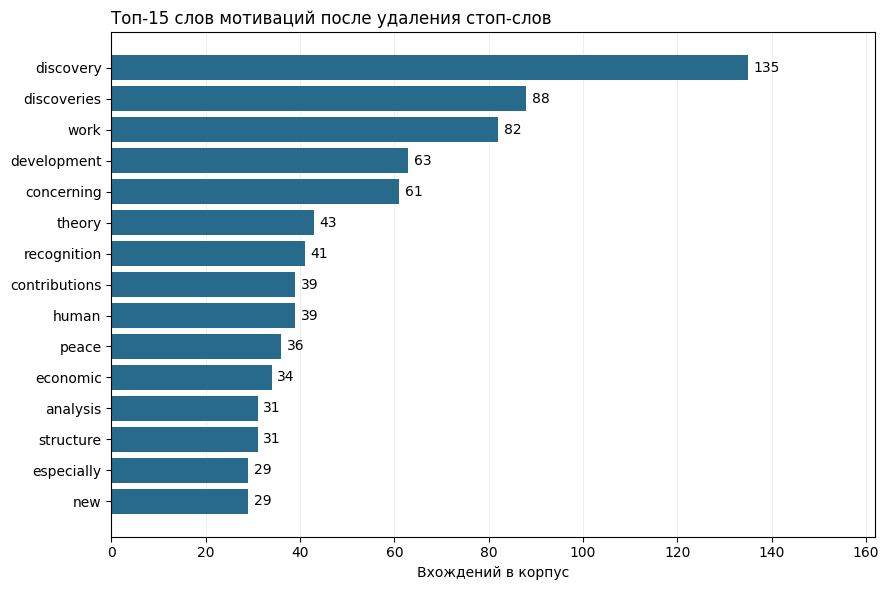

In [22]:
motivations = analyze_motivations(prize_rows, results_dir, show=True)

**Вывод.** Из 1036 награждений получилось **710 уникальных
текстов** после объединения общих мотиваций со-лауреатов.
До очистки лидируют `of` (901), `the` (866), `for` (777). После очистки чаще всего встречаются `discovery` (135), `discoveries` (88), `work` (82)
и `development` (63). В экономике выделяются `economic`, `analysis`, `theory`, в премии мира - `peace`, `efforts`, `international`, в литературе -
`human`, `life`, `poetry`. Совпадения топ-10 по категориям
приведены выше.

## 6. Финальная проверка

В конце ещё раз проверяем основные результаты. Сверяем количество лауреатов с метаданными API, проверяем уникальность ID, согласованность возрастной и гендерной статистики и количество элементов в итоговых рейтингах.

Если хотя бы одна из проверок не проходит, программа выдаёт ошибку.

In [23]:
assert len(laureates_data) == int(payload['meta']['count'])
assert not technical['duplicates']
assert age['total']['count'] == sum(
    row['count'] for row in age['by_decade']
)
assert gender['total']['count'] == len(filter_records(
    prepared, lambda row: row['type_'] == 'person',
))
assert len(motivations['original_top50']) == 50
assert len(motivations['cleaned_top50']) == 50
assert len(countries['top5']) == 5
print('Проверки согласованности итогов пройдены.')

Проверки согласованности итогов пройдены.


## 7. Итоговые выводы

1. **Страны**. Больше всего лауреатов связано с США - 306 человек и организаций с известной страной происхождения. Следом идут Великобритания, Германия, Франция и Япония. Разрыв между США и остальными странами довольно большой.

2. **Возраст**. В среднем первую Нобелевскую премию получают в 60,61 года. Возраст различается между категориями: раньше всего награждают физиков, а позже всего экономистов. В последние десятилетия средний возраст первой премии выше, чем в начале XX века, хотя рост происходил неравномерно.

3. **Гендер**. За всю историю женщины составляют 6,90% лауреатов-людей. Больше всего лауреаток в премии мира и литературе. В неполных 2020-х их доля уже составляет 19,51%.

4. **Мотивации**. После удаления общих английских слов чаще всего встречаются discovery, discoveries, work и development. При этом у разных категорий есть свои особенности: например, в текстах премии мира чаще встречается лексика, связанная с миром и международными усилиями, а в экономике - с анализом и теорией.

**Ограничения исследования**. Возраст рассчитывается приблизительно, поскольку мы используем только годы рождения и награждения. Страна показывает место рождения или основания, а не гражданство или страну проживания. Один человек может учитываться в нескольких категориях и десятилетиях, если получал премии в разные периоды. Кроме того, данные за 2020-е пока неполные.
